# A detailed HCP example notebook

This notebook contains the entire process for ASF Imaging. 


In [1]:
# Libraries
import os, sys
import json
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")
from asfimaging import ASFpipeline

In [2]:
print(ASFpipeline)
print(type(ASFpipeline))

<class 'asfimaging.pipeline.ASFpipeline.ASFpipeline'>
<class 'type'>


In [3]:
# Setup pipeline
path_config= "/work3/s165541/workspace/asf-imaging/configs/hcp_slice.json"
ASFImaging = ASFpipeline(path_config)

### Generate synthetic data

In [4]:
# 1. Generate synthetic data
X_train, y_train = ASFImaging.synthetic_train_data()

Number of unique b-values:  5
Number of unique gradient directions:  512
Number of unique b-values:  5
Number of unique gradient directions:  512


/work3/s165541/miniconda3/envs/dMRI1/lib/python3.8/site-packages/numba/core/ir_utils.py:2031: NumbaPendingDeprecationWarning: 
Encountered the use of a type that is scheduled for deprecation: type 'reflected list' found for argument 'mu' of function 'unitsphere2cart_1d'.

For more information visit http://numba.pydata.org/numba-doc/latest/reference/deprecation.html#deprecation-of-reflection-for-list-and-set-types

File "../asfimaging/dmipy/utils/utils.py", line 463:

def unitsphere2cart_1d(mu):
^

  warnings.warn(NumbaPendingDeprecationWarning(msg, loc=loc))
/work3/s165541/miniconda3/envs/dMRI1/lib/python3.8/site-packages/numba/core/ir_utils.py:2031: NumbaPendingDeprecationWarning: 
Encountered the use of a type that is scheduled for deprecation: type 'reflected list' found for argument 'mu' of function 'unitsphere2cart_1d'.

For more information visit http://numba.pydata.org/numba-doc/latest/reference/deprecation.html#deprecation-of-reflection-for-list-and-set-types

File "../asfimagi

Saved 200000 synthetic signals to /dtu-compute/thith/asf-imaging/data/hcp/synthetic_data


### Training RF regressor 

In [5]:
# 2. Build model and save
RF_regressor = ASFImaging.train(X_train, y_train)

### Features from real data

In [6]:
raw_data, raw_affine, mask = ASFImaging.data_extractor("axial")

Chosing the middle slice index 45
(140, 140, 1, 552)
(140, 140, 1)


In [7]:
features = ASFImaging.real_feature_extractor(raw_data, raw_affine, mask)

/work3/s165541/workspace/asf-imaging/notebooks/../asfimaging/features/rslbps.py:61: RuntimeWarning: invalid value encountered in divide
  shcoeff = shfit.fit_sh_all_data(np.nan_to_num(dwi_data[...,idxs_selection]/b0[...,np.newaxis]),
/work3/s165541/workspace/asf-imaging/notebooks/../asfimaging/shtools/sphericalharmonicsfit.py:230: UserWarning: It may be safer to use inputscale != 1 for numerical stability by making sure that input data is not too small nor too large!!
  warnings.warn('It may be safer to use inputscale != 1 for numerical stability by making sure that input data is not too small nor too large!!')


-> Include lb regularization with lambda 1e-06 and relaxed positivity constraints


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    9.4s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:   10.9s
[Parallel(n_jobs=12)]: Done 612 tasks      | elapsed:   14.9s


[Parallel(n_jobs=12)]: Done 1312 tasks      | elapsed:   20.9s


[Parallel(n_jobs=12)]: Done 2212 tasks      | elapsed:   28.8s


... (26 outputs left out)

[Parallel(n_jobs=12)]: Done 6984 tasks      | elapsed:  1.2min


[Parallel(n_jobs=12)]: Done 8585 out of 8585 | elapsed:  1.4min finished
/work3/s165541/workspace/asf-imaging/notebooks/../asfimaging/features/zonal_ratios.py:43: RuntimeWarning: invalid value encountered in divide
  ratios[...,count] = np.reshape(np.abs(signal_forward)/np.abs(signal_backward),(ratios[...,count]).shape)


(140, 140, 1, 91)
(140, 140, 1, 28)
0
(140, 140, 1, 1)
2
(140, 140, 1, 1)
4
(140, 140, 1, 1)
6
(140, 140, 1, 1)
8
(140, 140, 1, 1)
10
(140, 140, 1, 1)
12
(140, 140, 1, 1)
(140, 140, 1)
(140, 140, 1, 7) (8585, 7)
(140, 140, 1)
(140, 140, 1) (8585,)
(140, 140, 1)
(140, 140, 1) (8585,)
(140, 140, 1)
(140, 140, 1) (8585,)
(140, 140, 1)
(140, 140, 1) (8585,)
(140, 140, 1)
(140, 140, 1, 7) (8585, 7)
(140, 140, 1)
(140, 140, 1, 7) (8585, 7)


/work3/s165541/workspace/asf-imaging/notebooks/../asfimaging/features/means.py:37: RuntimeWarning: invalid value encountered in divide
  means[...,j] = np.mean(signal/b0[...,np.newaxis], axis=-1)
/work3/s165541/workspace/asf-imaging/notebooks/../asfimaging/features/variances.py:34: RuntimeWarning: invalid value encountered in divide
  variances[...,j] = np.var(signal/b0[...,np.newaxis], axis=-1)


In [8]:
print(features.shape)

(8585, 25)


### Predict using pre-train regressor

In [9]:
labels = ASFImaging.predict_from_features(features)

In [10]:
dpar, dperp, asf_calculated, asf_predicted = ASFImaging.save_maps(labels, raw_data, mask)

(140, 140, 1)


/work3/s165541/workspace/asf-imaging/notebooks/../asfimaging/model/asf.py:38: RuntimeWarning: invalid value encountered in divide
  data_b5000_normalized = data_b5000_mean/data_b0_mean
/work3/s165541/workspace/asf-imaging/notebooks/../asfimaging/model/asf.py:19: RuntimeWarning: invalid value encountered in divide
  m = np.exp(-b*d_perp) *np.sqrt(np.pi)/2 *(ssp.erf(np.sqrt(b*(d_par-d_perp))))/np.sqrt(b*(d_par-d_perp))


### Visualize MAPS

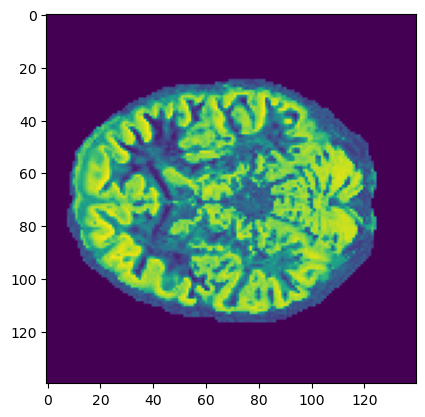

In [11]:
plt.imshow(dperp)

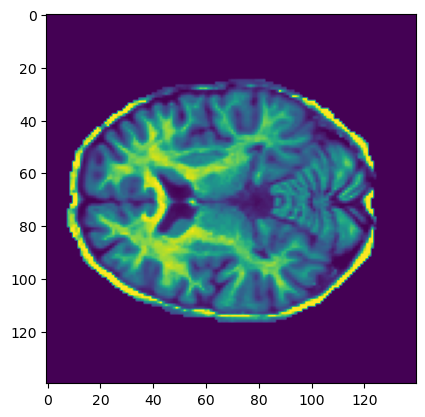

In [13]:
plt.imshow(asf_calculated)